# 🎵 Music Genre Classification — chạy toàn bộ pipeline

Điểm vào chính của dự án, tương đương `python main.py`.

**Luồng:** Clean → Feature → Preprocess → 5-fold OOF từng model → Ensemble → `submission.csv`

Trước khi chạy lần đầu: `pip install -r requirements.txt` rồi `pip install -e .`,
và đặt `train.csv`, `test.csv` vào `data/raw/`.

In [1]:
import sys, warnings
from pathlib import Path

ROOT = Path.cwd()
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))

# Tự nạp lại code khi file trong src/ thay đổi
%load_ext autoreload
%autoreload 2

import numpy as np
import pandas as pd
pd.set_option('display.max_columns', 100)
warnings.filterwarnings('ignore', category=FutureWarning)
print('Thư mục dự án:', ROOT)

Thư mục dự án: /Users/leanh/Documents/Machine Learning/Machine_learning_Group/Challege 2/MusicGenre


## Tham số chạy

In [2]:
MEMBER = 'team'          # tên bạn, để log ghi riêng cho từng người
CONFIG = None            # None = config/global_config.yaml, hoặc 'config/config_<ten>.yaml'
MODELS = None            # None = lấy từ run.models trong config, hoặc ['histgb', 'logreg']

from src.pipeline.Pipeline import MusicGenrePipeline, available_models
print('Model dùng được trên máy này:', available_models())

Model dùng được trên máy này: ['histgb', 'randomforest', 'extratrees', 'logreg', 'text', 'lightgbm', 'xgboost', 'catboost']


## Cách 1 — chạy một lệnh

Giống hệt `python main.py --member <ten>`.

In [3]:
out = MusicGenrePipeline(CONFIG, MEMBER).run(MODELS)
print('\nFile nộp Kaggle:', out)

Dữ liệu sau xử lý: train (14396, 29), test (3600, 29)


histgb_{'accuracy': 0.6867879966657405, 'acc_std': 0.005851191502754702, 'f1_macro': 0.7313069174647758, 'log_loss': 0.8559539704594662}


randomforest_{'accuracy': 0.6772020005557099, 'acc_std': 0.006755219702494853, 'f1_macro': 0.7176853581095977, 'log_loss': 0.9345416059180051}


extratrees_{'accuracy': 0.6755348707974438, 'acc_std': 0.005756734208226718, 'f1_macro': 0.7134083816322889, 'log_loss': 0.9329538321182225}


logreg_{'accuracy': 0.6600444567935537, 'acc_std': 0.007216293669646475, 'f1_macro': 0.6972486352269882, 'log_loss': 0.935153928720665}


text_{'accuracy': 0.44505418171714367, 'acc_std': 0.005003941143821746, 'f1_macro': 0.46010151138494476, 'log_loss': 1.5789739717364333}


... (3 outputs left out)

ensemble_{'method': 'stacking', 'accuracy': 0.7021394831897749, 'f1_macro': 0.7533759008050427, 'log_loss': 0.8489144825650403, 'weights': {}}



 class  precision  recall    f1  support
     0      0.839   0.894 0.865      500
     1      0.525   0.305 0.386     1098
     2      0.775   0.689 0.729     1018
     3      0.951   0.910 0.930      322
     4      0.902   0.829 0.864      310
     5      0.816   0.800 0.808     1157
     6      0.557   0.617 0.586     2069
     7      0.974   0.959 0.966      461
     8      0.790   0.728 0.758     1483
     9      0.719   0.673 0.695     2019
    10      0.652   0.756 0.700     3959


{'submission_rows': 3600, 'pred_distribution': {0: 139, 1: 160, 2: 225, 3: 78, 4: 77, 5: 263, 6: 556, 7: 105, 8: 319, 9: 483, 10: 1195}}



File nộp Kaggle: /Users/leanh/Documents/Machine Learning/Machine_learning_Group/Challege 2/MusicGenre/SUBMIT-summarize_report/submission.csv


---

## Cách 2 — chạy từng bước

### Bước 1: Clean → Feature → Preprocess

In [4]:
pipe = MusicGenrePipeline(CONFIG, MEMBER)
X, y, X_test, test_ids = pipe.prepare()
print('X:', X.shape, '| X_test:', X_test.shape)
print(pipe.cleaner.summary())
X.head()

X: (14396, 29) | X_test: (3600, 29)
- Dòng train: 14396 (bỏ 0 dòng trùng hoàn toàn)
- Dòng test: 3600
- Dòng train ghi thời lượng bằng phút: 2075
- Giá trị thiếu trước khi xử lý: {'Popularity': 333, 'key': 1609, 'instrumentalness': 3541}



,Artist Name,Track Name,Popularity,danceability,energy,key,loudness,mode,speechiness,acousticness,instrumentalness,liveness,valence,tempo,time_signature,duration_is_min,duration_ms,instr_missing,pop_missing,pair,track_len,track_words,has_feat,has_version,non_ascii_ratio,artist_multi,energy_x_loud,acoustic_minus_energy,duration_min
0,Marina Maximilian,Not Afraid,37.0,0.334,0.536,9,-6.649,0,0.0381,0.378000,0.0000,0.106,0.235,152.429,4,0,204947.0,1,0,Marina Maximilian || Not Afraid,10,2,0,0,0.0,0,0.476602,-0.158000,3.415783
1,The Black Keys,Howlin' for You,67.0,0.725,0.747,11,-5.545,1,0.0876,0.027200,0.0468,0.104,0.380,132.921,4,0,191956.0,0,0,The Black Keys || Howlin' for You,15,3,0,0,0.0,0,0.677965,-0.719800,3.199267
2,Royal & the Serpent,phuck u,44.0,0.584,0.804,7,-6.094,1,0.0619,0.000968,0.6350,0.284,0.635,159.953,4,0,161037.0,0,1,Royal & the Serpent || phuck u,7,2,0,0,0.0,1,0.722340,-0.803032,2.683950
3,Detroit Blues Band,Missing You,12.0,0.515,0.308,0,-14.711,1,0.0312,0.907000,0.0213,0.300,0.501,172.472,3,0,298093.0,0,0,Detroit Blues Band || Missing You,11,2,0,0,0.0,0,0.232484,0.599000,4.968217
4,Coast Contra,My Lady,48.0,0.565,0.777,6,-5.096,0,0.2490,0.183000,0.0000,0.211,0.619,88.311,4,0,254145.0,1,0,Coast Contra || My Lady,7,2,0,0,0.0,0,0.711007,-0.594000,4.235750


### Bước 2: cross-validation từng model

Target encoding nằm **bên trong** pipeline của từng model, nên trong mỗi fold nó chỉ
học từ phần huấn luyện của fold đó. Nhờ vậy xác suất OOF không bị rò rỉ nhãn.

In [5]:
from src.evaluation.Evaluation import Evaluator
from src.pipeline.Pipeline import MODELS as REG

cfg = pipe.cfg
names = [n for n in (MODELS or cfg['run']['models']) if n in REG]
results = {}
for n in names:
    results[n] = Evaluator.oof_predict(lambda k=n: REG[k](cfg, pipe.pre), X, y, X_test,
                                       n_folds=cfg['split']['n_folds'], seed=cfg['project']['seed'])
    r = results[n]
    print(f"{n:13s} accuracy={r['accuracy']:.4f} ± {r['acc_std']:.4f}   f1_macro={r['f1_macro']:.4f}   log_loss={r['log_loss']:.4f}")
Evaluator.compare(results)

histgb        accuracy=0.6868 ± 0.0059   f1_macro=0.7313   log_loss=0.8560


randomforest  accuracy=0.6772 ± 0.0068   f1_macro=0.7177   log_loss=0.9345


extratrees    accuracy=0.6755 ± 0.0058   f1_macro=0.7134   log_loss=0.9330


logreg        accuracy=0.6600 ± 0.0072   f1_macro=0.6972   log_loss=0.9352


text          accuracy=0.4451 ± 0.0050   f1_macro=0.4601   log_loss=1.5790


lightgbm      accuracy=0.6895 ± 0.0031   f1_macro=0.7378   log_loss=1.0265


,model,accuracy,acc_std,f1_macro,log_loss
0,lightgbm,0.6895,0.0031,0.7378,1.0265
1,histgb,0.6868,0.0059,0.7313,0.8560
2,randomforest,0.6772,0.0068,0.7177,0.9345
3,extratrees,0.6755,0.0058,0.7134,0.9330
4,logreg,0.6600,0.0072,0.6972,0.9352
5,text,0.4451,0.0050,0.4601,1.5790


### Bước 3: so sánh các cách kết hợp

In [6]:
from src.ensemble.Ensemble import compare_methods, Stacking

classes = results[names[0]]['classes']
oof = {k: v['oof'] for k, v in results.items()}
compare_methods(oof, y, classes)

,method,accuracy,log_loss,weights
0,stacking,0.7021,0.8489,{}
1,voting,0.6999,0.8907,"{'histgb': 0.167, 'randomforest': 0.167, 'extr..."
2,blending,0.6944,0.8344,"{'histgb': 0.5, 'randomforest': 0.0, 'extratre..."
3,(đơn lẻ) lightgbm,0.6895,1.0265,{}
4,(đơn lẻ) histgb,0.6868,0.8560,{}
5,(đơn lẻ) randomforest,0.6772,0.9345,{}
6,(đơn lẻ) extratrees,0.6755,0.9330,{}
7,(đơn lẻ) logreg,0.6600,0.9352,{}
8,(đơn lẻ) text,0.4451,1.5790,{}


### Bước 4: kết quả theo từng lớp và ma trận nhầm lẫn

,class,precision,recall,f1,support
0,0,0.839,0.894,0.865,500
1,1,0.525,0.305,0.386,1098
2,2,0.775,0.689,0.729,1018
3,3,0.951,0.910,0.930,322
4,4,0.902,0.829,0.864,310
5,5,0.816,0.800,0.808,1157
6,6,0.557,0.617,0.586,2069
7,7,0.974,0.959,0.966,461
8,8,0.790,0.728,0.758,1483
9,9,0.719,0.673,0.695,2019


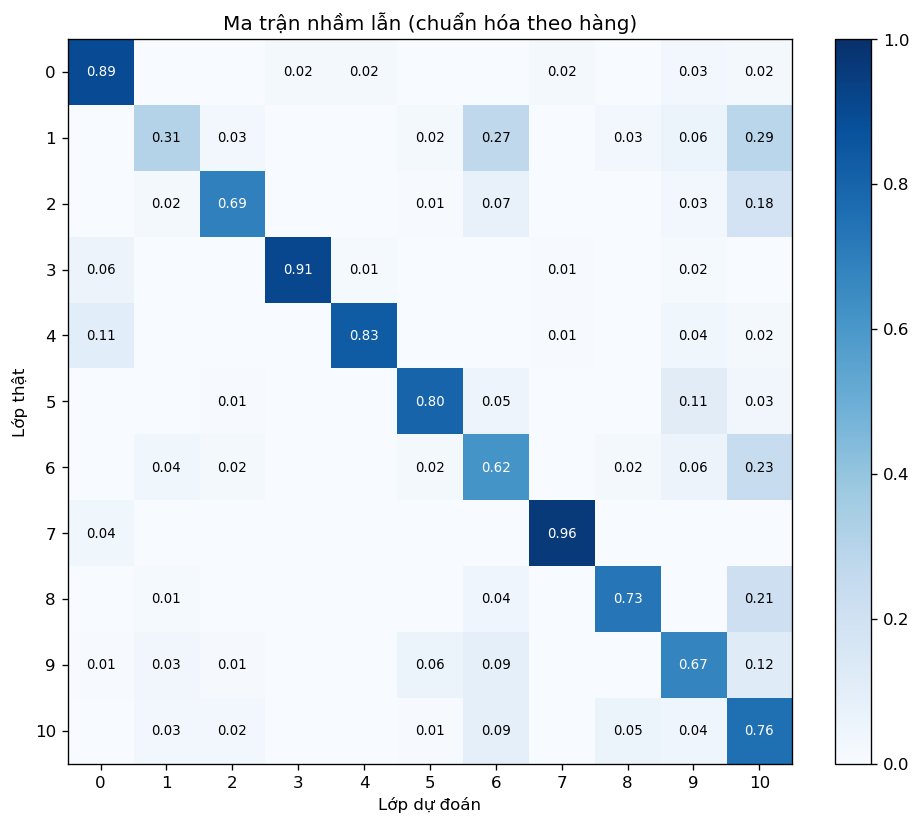

In [7]:
from src.utils.data_loader import get_path

final_oof = Stacking().oof_proba(oof, y)
display(Evaluator.per_class(y, final_oof, classes))
Evaluator.plot_confusion(y, final_oof, classes, fig_dir=get_path(cfg, 'figures'))
from IPython.display import Image
Image(str(get_path(cfg, 'figures') / 'confusion_matrix.png'))

---

## Sau khi chạy

- [ ] Nộp `SUBMIT-summarize_report/submission.csv` lên Kaggle
- [ ] Ghi một dòng vào `reports/results_summary.md`
- [ ] Đối chiếu điểm Kaggle với accuracy OOF

Độ lệch chuẩn accuracy giữa các fold khoảng 0,004 – 0,007. Cải thiện nhỏ hơn mức đó chưa thể kết luận là thật.